# Step 6 — Penalized logistic regression (ridge and lasso)
**Owner:** Rishi. **Input:** `clean_table.csv` (Denver, Steps 1–3). **Output:** model comparison table, odds ratios, chosen lasso C (used by Step 8).

**Question:** using all 446 sensors at once, how well can we predict fail vs pass, and which sensors does the model lean on?

**Testing setup:**
* Denver's split is reused exactly (80/20, stratified, seed 42) → 1,253 train units (83 fails), 314 test units (21 fails).
* The 20% test set is **locked**: it is used once, at the end, to report final numbers.
* Everything that needs tuning (the penalty C, the alarm threshold) is chosen with **5-fold CV repeated 10 times on the 80% train set** (50 train/validation splits).
* Filling blanks and scaling are refit inside every split (Pipeline), so no information leaks from validation into training.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, balanced_accuracy_score,
                             matthews_corrcoef, brier_score_loss, confusion_matrix,
                             recall_score, precision_score, precision_recall_curve, roc_curve)
warnings.filterwarnings("ignore")      # silences sklearn convergence / version warnings

SEED = 42
N_REPEATS = 10                         # 5-fold x 10 repeats = 50 splits. Set to 2 for a quick test run.
C_GRID = np.logspace(-3, 0.5, 15)      # lasso penalty strengths; small C = strong penalty
RIDGE_GRID = np.logspace(-6, 0, 13)    # ridge needs much stronger penalties (it keeps all 446 sensors)
TUNE_METRIC = "roc_auc"                # what picks C. See note in 6.3: PR-AUC was too flat/noisy to choose C.

## Load the data and reuse Denver's split

In [2]:
clean = pd.read_csv("clean_table.csv")
sensors = [c for c in clean.columns if c.startswith("Sensor_")]
X = clean[sensors]
y = clean["label"]                     # 1 = fail, 0 = pass

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)   # identical to Denver's notebook

print("sensors:", len(sensors))
print("train:", X_train.shape, "fails:", y_train.sum())
print("test: ", X_test.shape, "fails:", y_test.sum())

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED)

sensors: 446
train: (1253, 446) fails: 83
test:  (314, 446) fails: 21


## Helpers
* `prep()` = Denver's Step 3: fill blanks with the median, then scale each sensor to mean 0, SD 1. Inside a Pipeline it is refit on each training split only.
* `cv_scores()` runs a model over all 50 splits and returns the average and spread of each metric.

In [3]:
def prep():
    return [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]

def logit(penalty, C, solver="liblinear"):
    return LogisticRegression(penalty=penalty, C=C, solver=solver,
                              class_weight="balanced", max_iter=5000)

SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "bal_acc": "balanced_accuracy"}

def cv_scores(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING,
                       return_train_score=True, n_jobs=-1)
    return {k: (r[f"test_{k}"].mean(), r[f"test_{k}"].std(), r[f"train_{k}"].mean()) for k in SCORING}

results = {}       # model name -> cv scores

## 6.1 Baselines — the floor every model must beat
* **Always-pass:** predicts the 6.6% fail rate for every unit. PR-AUC of this model = the fail rate (~0.066). Anything near that has learned nothing.
* **Best single sensor:** the one sensor that, alone, best separates fails from passes.

In [4]:
results["Always-pass (baseline)"] = cv_scores(DummyClassifier(strategy="prior"))

# Rank sensors one at a time with a fast 5-fold check, then score the winner on the full 50 splits.
quick = RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=SEED)
single = {}
for s in sensors:
    m = Pipeline(prep() + [("lr", LogisticRegression(class_weight="balanced"))])
    single[s] = cross_validate(m, X_train[[s]], y_train, cv=quick,
                               scoring="average_precision")["test_score"].mean()
best_sensor = max(single, key=single.get)
print("best single sensor:", best_sensor, "| quick PR-AUC:", round(single[best_sensor], 3))

r = cross_validate(Pipeline(prep() + [("lr", LogisticRegression(class_weight="balanced"))]),
                   X_train[[best_sensor]], y_train, cv=cv, scoring=SCORING,
                   return_train_score=True, n_jobs=-1)
results[f"Best single sensor ({best_sensor})"] = {k: (r[f"test_{k}"].mean(), r[f"test_{k}"].std(),
                                                      r[f"train_{k}"].mean()) for k in SCORING}
# Note: picking the best sensor on the same train data makes this baseline slightly optimistic.

best single sensor: Sensor_065 | quick PR-AUC: 0.174


## 6.2 Small unpenalized logistic regression (12 sensors)
Rule of thumb: ~10 fails per variable → with 83 train fails, about 8–12 sensors. The 12 are picked inside each split.
Watch the gap between **train** and **CV** score: that gap is overfitting.

In [5]:
small = Pipeline(prep() + [("pick", SelectKBest(f_classif, k=12)),
                           ("lr", LogisticRegression(penalty=None, max_iter=5000, class_weight="balanced"))])
results["Logistic, 12 sensors, no penalty"] = cv_scores(small)
print("train PR-AUC: %.3f | CV PR-AUC: %.3f" % (results["Logistic, 12 sensors, no penalty"]["pr_auc"][2],
                                                 results["Logistic, 12 sensors, no penalty"]["pr_auc"][0]))

train PR-AUC: 0.233 | CV PR-AUC: 0.147


## 6.3–6.5 Ridge and lasso: try every C, pick the best
* **Ridge (L2):** shrinks all 446 coefficients towards 0; keeps every sensor.
* **Lasso (L1):** sets most coefficients to exactly 0 → a shortlist of sensors.
* For each C we record CV PR-AUC and ROC-AUC (mean and standard error over 50 splits).
* **Best C** = highest mean `TUNE_METRIC`. **One-SE C** = the strongest penalty (smallest C) whose score is within one standard error of the best → simpler, more stable model. Step 8 uses lasso's one-SE C.

**Deviation from the manual (documented on purpose):** the manual tunes C on PR-AUC. On this data the PR-AUC curve is flat (≈0.15–0.17 whether lasso keeps 4 sensors or 200), because each validation fold has only ~17 fails, so it cannot tell us how many sensors to keep. ROC-AUC uses the full ranking of all units, is less noisy, and shows a clear peak, so we tune on ROC-AUC and still **report** PR-AUC as the main result.

In [6]:
def tune(penalty, solver, grid):
    rows = []
    for C in grid:
        model = Pipeline(prep() + [("lr", logit(penalty, C, solver))])
        r = cross_validate(model, X_train, y_train, cv=cv,
                           scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
                           return_estimator=(penalty == "l1"), n_jobs=-1)
        n = len(r["test_pr_auc"])
        row = {"C": C}
        for k in ["pr_auc", "roc_auc"]:
            row[k] = r[f"test_{k}"].mean()
            row[f"{k}_se"] = r[f"test_{k}"].std(ddof=1) / np.sqrt(n)
        if penalty == "l1":
            row["n_sensors"] = np.mean([(e.named_steps["lr"].coef_ != 0).sum() for e in r["estimator"]])
        rows.append(row)
    path = pd.DataFrame(rows)
    m = TUNE_METRIC
    best = path.loc[path[m].idxmax()]
    one_se_C = path.loc[path[m] >= best[m] - best[f"{m}_se"], "C"].min()
    return path, best.C, one_se_C

ridge_path, ridge_best_C, ridge_1se_C = tune("l2", "lbfgs", RIDGE_GRID)
lasso_path, lasso_best_C, lasso_1se_C = tune("l1", "liblinear", C_GRID)

print(f"ridge: best C = {ridge_best_C:.4g}, one-SE C = {ridge_1se_C:.4g}")
print(f"lasso: best C = {lasso_best_C:.4g}, one-SE C = {lasso_1se_C:.4g}")
print(lasso_path.round(4).to_string(index=False))

ridge: best C = 1e-06, one-SE C = 1e-06
lasso: best C = 0.05623, one-SE C = 0.03162
     C  pr_auc  pr_auc_se  roc_auc  roc_auc_se  n_sensors
0.0010  0.0662     0.0003   0.5000      0.0000       0.00
0.0018  0.0662     0.0003   0.5000      0.0000       0.00
0.0032  0.0662     0.0003   0.5000      0.0000       0.00
0.0056  0.1008     0.0060   0.5666      0.0108       0.50
0.0100  0.1628     0.0072   0.6724      0.0086       3.54
0.0178  0.1510     0.0063   0.6669      0.0076      17.56
0.0316  0.1675     0.0078   0.6847      0.0074      45.96
0.0562  0.1648     0.0070   0.6874      0.0073      77.30
0.1000  0.1640     0.0067   0.6730      0.0069     108.80
0.1778  0.1565     0.0065   0.6608      0.0066     138.04
0.3162  0.1519     0.0066   0.6436      0.0069     161.44
0.5623  0.1464     0.0063   0.6309      0.0072     182.00
1.0000  0.1483     0.0068   0.6260      0.0075     195.72
1.7783  0.1482     0.0068   0.6248      0.0079     204.28
3.1623  0.1472     0.0070   0.6234      0.0080

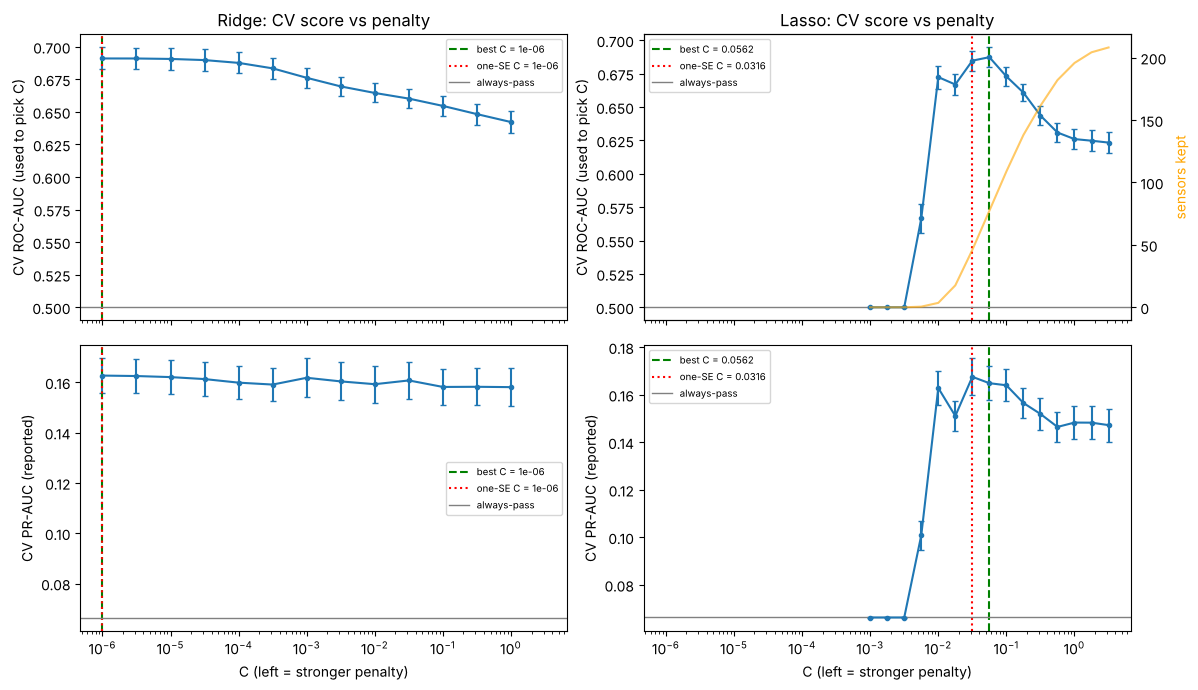

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for col, (path, name, b, o) in enumerate([(ridge_path, "Ridge", ridge_best_C, ridge_1se_C),
                                          (lasso_path, "Lasso", lasso_best_C, lasso_1se_C)]):
    for row, (k, lab, base) in enumerate([("roc_auc", "CV ROC-AUC (used to pick C)", 0.5),
                                          ("pr_auc", "CV PR-AUC (reported)", y_train.mean())]):
        a = ax[row, col]
        a.errorbar(path.C, path[k], yerr=path[f"{k}_se"], marker="o", ms=3, capsize=2)
        a.axvline(b, ls="--", c="green", label=f"best C = {b:.3g}")
        a.axvline(o, ls=":", c="red", label=f"one-SE C = {o:.3g}")
        a.axhline(base, c="grey", lw=1, label="always-pass")
        a.set_xscale("log"); a.set_ylabel(lab); a.legend(fontsize=7)
        if row == 0: a.set_title(f"{name}: CV score vs penalty")
        if row == 1: a.set_xlabel("C (left = stronger penalty)")
    if name == "Lasso":
        a2 = ax[0, 1].twinx(); a2.plot(path.C, path.n_sensors, c="orange", alpha=.6)
        a2.set_ylabel("sensors kept", color="orange")
plt.tight_layout(); plt.savefig("step6_lambda_paths.png", dpi=150); plt.show()

In [8]:
models = {
    "Ridge (best C)":   Pipeline(prep() + [("lr", logit("l2", ridge_best_C, "lbfgs"))]),
    "Lasso (best C)":   Pipeline(prep() + [("lr", logit("l1", lasso_best_C))]),
    "Lasso (one-SE C)": Pipeline(prep() + [("lr", logit("l1", lasso_1se_C))]),
}
for name, m in models.items():
    results[name] = cv_scores(m)

## Model comparison (cross-validation on the 80% train set)
PR-AUC is the main score: it focuses on how well fails are found. Always-pass scores ~0.066.

In [9]:
table = pd.DataFrame({name: {"CV PR-AUC": f"{v['pr_auc'][0]:.3f} ± {v['pr_auc'][1]:.3f}",
                             "train PR-AUC": f"{v['pr_auc'][2]:.3f}",
                             "CV ROC-AUC": f"{v['roc_auc'][0]:.3f} ± {v['roc_auc'][1]:.3f}",
                             "CV balanced acc": f"{v['bal_acc'][0]:.3f} ± {v['bal_acc'][1]:.3f}"}
                      for name, v in results.items()}).T
table.to_csv("step6_model_table_cv.csv")
table

,CV PR-AUC,train PR-AUC,CV ROC-AUC,CV balanced acc
Always-pass (baseline),0.066 ± 0.002,0.066,0.500 ± 0.000,0.500 ± 0.000
Best single sensor (Sensor_065),0.180 ± 0.071,0.147,0.562 ± 0.068,0.563 ± 0.052
"Logistic, 12 sensors, no penalty",0.147 ± 0.040,0.233,0.659 ± 0.058,0.631 ± 0.052
Ridge (best C),0.163 ± 0.048,0.304,0.691 ± 0.059,0.610 ± 0.052
Lasso (best C),0.165 ± 0.049,0.509,0.687 ± 0.051,0.627 ± 0.048
Lasso (one-SE C),0.168 ± 0.055,0.395,0.685 ± 0.052,0.631 ± 0.049


## 6.6 Odds ratios — how much each sensor moves the odds of failure
Fit the one-SE lasso on the full train set. Because sensors are scaled to SD 1, `exp(coefficient)` = **how much the odds of failure multiply when the sensor reads one standard deviation higher.**
* 1.5 → odds of failure 50% higher. 0.7 → 30% lower. 1.0 → no effect (dropped by lasso).

In [10]:
final_lasso = models["Lasso (one-SE C)"].fit(X_train, y_train)
coef = pd.Series(final_lasso.named_steps["lr"].coef_.ravel(), index=sensors)
odds = pd.DataFrame({"coef": coef, "odds_ratio_per_SD": np.exp(coef)})
odds = odds[odds.coef != 0].reindex(odds.coef.abs().sort_values(ascending=False).index).dropna()
odds["direction"] = np.where(odds.coef > 0, "higher reading -> more fails", "lower reading -> more fails")

# compare signs with ridge for the same sensors (manual's check: top-10 signs should agree)
final_ridge = models["Ridge (best C)"].fit(X_train, y_train)
ridge_coef = pd.Series(final_ridge.named_steps["lr"].coef_.ravel(), index=sensors)
odds["ridge_agrees_on_sign"] = np.sign(ridge_coef[odds.index]) == np.sign(odds.coef)

# attach Step 4 team, if the team file is present
try:
    teams = pd.read_csv("sensor_teams.csv").set_index("sensor")
    odds["team_leader"] = teams.loc[odds.index, "leader"]
    odds["team_size"] = teams.loc[odds.index, "team_size"]
except FileNotFoundError:
    pass

print("sensors kept by one-SE lasso:", len(odds))
print("top-10 sign agreement with ridge:", odds.ridge_agrees_on_sign.head(10).sum(), "/ 10")
odds.to_csv("step6_odds_ratios.csv")
odds.head(15).round(3)

sensors kept by one-SE lasso: 53
top-10 sign agreement with ridge: 10 / 10


,coef,odds_ratio_per_SD,direction,ridge_agrees_on_sign,team_leader,team_size
Sensor_060,0.400,1.492,higher reading -> more fails,True,Sensor_060,1
Sensor_130,0.337,1.401,higher reading -> more fails,True,Sensor_130,1
Sensor_065,0.227,1.255,higher reading -> more fails,True,Sensor_065,1
Sensor_282,-0.176,0.838,lower reading -> more fails,True,Sensor_282,1
Sensor_076,0.176,1.193,higher reading -> more fails,True,Sensor_076,1
Sensor_122,0.166,1.181,higher reading -> more fails,True,Sensor_122,1
Sensor_104,0.154,1.167,higher reading -> more fails,True,Sensor_104,1
Sensor_434,0.147,1.159,higher reading -> more fails,True,Sensor_434,1
Sensor_481,-0.135,0.874,lower reading -> more fails,True,Sensor_481,1
Sensor_456,0.133,1.143,higher reading -> more fails,True,Sensor_184,3


## 6.7 Choosing the alarm threshold
With class weights the model outputs a "risk score". We pick the cut-off on **out-of-fold** scores from the train set (never the test set), at two operating points:
1. **Catch 80% of fails** (high recall, more false alarms)
2. **Best balanced accuracy** (average of fail-catch rate and pass-correct rate)

In [11]:
# Each model gets its own thresholds (their scores are on different scales).
def pick_thresholds(model):
    oof = cross_val_predict(model, X_train, y_train,
                            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                            method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    t80 = thr[np.where(rec[:-1] >= 0.80)[0].max()]          # highest cut-off still catching >= 80%
    fpr, tpr, thr_roc = roc_curve(y_train, oof)
    tbal = thr_roc[np.argmax((tpr + (1 - fpr)) / 2)]
    return {"80% recall": t80, "best bal. acc": tbal}

model_thresholds = {name: pick_thresholds(m) for name, m in models.items()}
pd.DataFrame(model_thresholds).round(3)

,Ridge (best C),Lasso (best C),Lasso (one-SE C)
80% recall,0.499,0.204,0.353
best bal. acc,0.500,0.558,0.508


## Final check on the locked 20% test set (used once)
314 units, 21 fails. With only 21 fails, each missed fail moves recall by ~5 points, so read these as rough.

In [12]:
def test_report(model, name, thresholds):
    p = model.fit(X_train, y_train).predict_proba(X_test)[:, 1]
    out = {"model": name, "test PR-AUC": average_precision_score(y_test, p),
           "test ROC-AUC": roc_auc_score(y_test, p), "Brier": brier_score_loss(y_test, p)}
    cms = {}
    for label, t in thresholds.items():
        pred = (p >= t).astype(int)
        out[f"recall @{label}"] = recall_score(y_test, pred)
        out[f"precision @{label}"] = precision_score(y_test, pred, zero_division=0)
        out[f"balanced error @{label}"] = 1 - balanced_accuracy_score(y_test, pred)
        out[f"MCC @{label}"] = matthews_corrcoef(y_test, pred)
        cms[label] = confusion_matrix(y_test, pred)
    return out, cms, p

rows, all_cms, probs = [], {}, {}
for name, m in models.items():
    out, cms, p = test_report(m, name, model_thresholds[name])
    rows.append(out); all_cms[name] = cms; probs[name] = p
base_p = np.full(len(y_test), y_train.mean())
rows.insert(0, {"model": "Always-pass (baseline)", "test PR-AUC": average_precision_score(y_test, base_p),
                "test ROC-AUC": 0.5, "Brier": brier_score_loss(y_test, base_p)})
test_table = pd.DataFrame(rows).set_index("model")
test_table.to_csv("step6_model_table_test.csv")
test_table.round(3).T

model,Always-pass (baseline),Ridge (best C),Lasso (best C),Lasso (one-SE C)
test PR-AUC,0.067,0.198,0.199,0.191
test ROC-AUC,0.500,0.733,0.679,0.732
Brier,0.062,0.250,0.150,0.175
recall @80% recall,NaN,0.762,0.762,0.810
precision @80% recall,NaN,0.096,0.083,0.100
balanced error @80% recall,NaN,0.377,0.421,0.356
MCC @80% recall,NaN,0.123,0.081,0.144
recall @best bal. acc,NaN,0.667,0.286,0.524
precision @best bal. acc,NaN,0.110,0.130,0.164
balanced error @best bal. acc,NaN,0.359,0.425,0.334


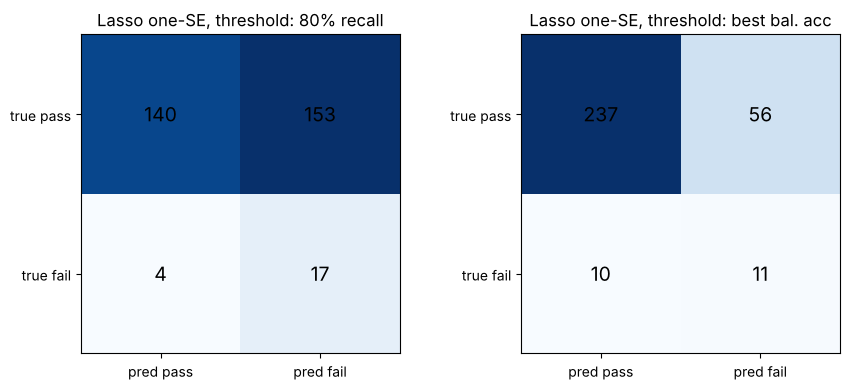

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, (label, cm) in zip(ax, all_cms["Lasso (one-SE C)"].items()):
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
    a.set_xticks([0, 1], ["pred pass", "pred fail"]); a.set_yticks([0, 1], ["true pass", "true fail"])
    a.set_title(f"Lasso one-SE, threshold: {label}")
plt.tight_layout(); plt.savefig("step6_confusion_matrices.png", dpi=150); plt.show()

## 6.8 Calibration and the published yardstick
* **Calibration:** when the model says "30% risk", do ~30% of those units fail? Class weights (`balanced`) deliberately push every score up (the model behaves as if half the units fail), so expect the curve far below the diagonal and a Brier score worse than always-pass. That's fine for ranking units and sensors, but the raw scores must not be read as true failure probabilities.
* **Yardstick:** `secom.names` reports a balanced error rate of ~33–35% (40 features, kernel ridge). We compare our test balanced error against that.

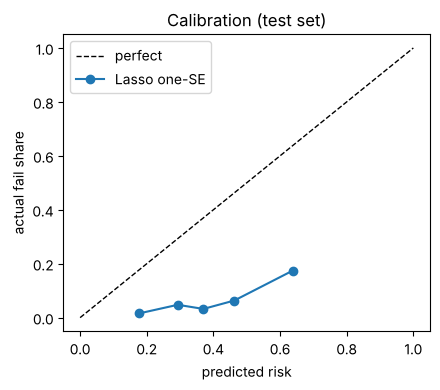

Lasso one-SE balanced error on test: 33.4%  (published baseline: ~33–35%)


In [14]:
frac_pos, mean_pred = calibration_curve(y_test, probs["Lasso (one-SE C)"], n_bins=5, strategy="quantile")
plt.figure(figsize=(4.5, 4))
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
plt.plot(mean_pred, frac_pos, marker="o", label="Lasso one-SE")
plt.xlabel("predicted risk"); plt.ylabel("actual fail share"); plt.legend(); plt.title("Calibration (test set)")
plt.tight_layout(); plt.savefig("step6_calibration.png", dpi=150); plt.show()

ber = test_table.loc["Lasso (one-SE C)", "balanced error @best bal. acc"]
print(f"Lasso one-SE balanced error on test: {ber:.1%}  (published baseline: ~33–35%)")

## Save the chosen penalty for Step 8

In [15]:
pd.Series({"lasso_best_C": lasso_best_C, "lasso_one_se_C": lasso_1se_C,
           "ridge_best_C": ridge_best_C, "ridge_one_se_C": ridge_1se_C}).to_csv("step6_chosen_C.csv", header=["value"])
print(open("step6_chosen_C.csv").read())

,value
lasso_best_C,0.056234132519034905
lasso_one_se_C,0.03162277660168379
ridge_best_C,1e-06
ridge_one_se_C,1e-06

